# Example: A Rule Switch in a Wolfram Market
In this example, we simulate the Wolfram market, an agent-based model in which interior traders on a grid act on the intentions of their four neighbors. We change one entry of the rule that a fraction of the interior traders follow, and watch the grid and the share price.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Watch a rule switch spread:__ Run a switched market and its control, and use the grid at several steps to say where the Sell intention starts and how it spreads.
> * __Explain the path of the share price:__ Compare the share price of the switched market with its control, and use the filled and unfilled orders to explain why the price stops falling.
> * __Bring in fresh players:__ Replace a fraction of the traders with fresh players after the share price has leveled off, and compare the share price with and without the fresh players.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
Next, let's set the constants. The live market uses a deep dealer and active edge traders, who buy when the share price is well below its recent average and sell when it is well above it.

Each step lasts `Δt` years, and the default is one minute of trading. At each step, the dealer's share price also changes by a random amount, the __noise__, with annualized volatility `σ_S`. The noise added in one step has standard deviation $\sigma_{S}\sqrt{\Delta t}$, and a longer step gets more noise.

Change the parameters and run the cells again. Every task runs live and follows the constants:

In [2]:
# the rules -
# baseline_rule = 19280; # rule number that every interior trader follows before the switch, from 0 to 19682; the default is the baseline rule of the lecture
# switch_rule = 19286; # rule number that the switching traders follow after the switch; the default is the switch rule of the lecture

# Case: a bubble that pops. Under Rule 19287, nearly every trader intends to buy and the share price rises.
# Rule 19341 changes one entry of Rule 19287: at sum 3, a trader sells instead of buys.
# Remove the # from the two lines below to run this case -
baseline_rule = 19287;
switch_rule = 19341;

# Case: a market that falls when traders stop buying. Under Rule 19257, nearly every trader intends to buy.
# Rule 19258 changes one entry of Rule 19257: at sum 0, a trader holds instead of buys.
# Remove the # from the two lines below to run this case -
# baseline_rule = 19257;
# switch_rule = 19258;

# Case: a market that falls when few traders switch. Under Rule 19289, about half of the traders hold and most of the others intend to buy.
# Rule 19298 changes one entry of Rule 19289: at sum 2, a trader sells instead of holds.
# Remove the # from the two lines below to run this case, and try a small f, for example 0.10 -
# baseline_rule = 19289;
# switch_rule = 19298;

# the live market -
L = 64; # grid size (L × L traders, including the edge)
f = 0.25; # fraction of interior traders that switch to switch_rule
h = 100.0; # dealer depth; a small value (for example 1.0) makes the price move a long way for a given net order
boundary_mode = :endogenous; # edge traders: :endogenous (active), :hold (held), or :random (random draws)
random_probabilities = (1/3, 1/3, 1/3); # probabilities of (Buy, Hold, Sell) for :random edge traders; ignored otherwise
seed = 1; # starting market; each seed gives a different random start
t_pre = 1000; # steps before the switch
t_post = 3000; # steps after the switch
snapshot_every = 5; # we save the grid every 5 steps
first_step_to_plot = 100; # first step shown in the plots of Tasks 2 and 3; the earlier steps are the startup from the random starting market

# the time step and the noise in the dealer's share price -
Δt = 1/(252*390); # length of one step (years), one minute of a 390-minute trading day
σ_S = 0.40; # annualized volatility of the noise in the dealer's share price (1/√yr); the noise added in one step has standard deviation σ_S√Δt, and 0.0 gives no noise

# the starting markets in Task 2 -
L_small = 32; # a smaller grid, so that 20 markets run in a few seconds
seeds = 1:20; # the starting markets

# the fresh players in Task 3 -
recovery_rule = 0; # rule number that the fresh players follow, from 0 to 19682; Rule 0 is Buy at every sum, and baseline_rule is the rule from before the switch
fresh_fraction = 0.25; # fraction of interior traders that fresh players replace
t_fresh = 2000; # the fresh players arrive after this step

# colors used in every plot -
color_switched = :red; # the switched market
color_control = :navy; # the control market, which never switches
color_fresh = :green4; # the switched market with fresh players
intention_colors = [parse(Colorant, "#0072B2"), parse(Colorant, "#AAAAAA"), parse(Colorant, "#D55E00")]; # Buy is blue, Hold is gray, Sell is orange

___

## Task 1: Watch a Rule Switch Spread
In this task, we run a switched market and its control, and watch the Sell intention spread across the grid.

In a __rule switch__, all interior traders follow the rule `baseline_rule` until the switch step, and then a fraction $f$ of them change to the rule `switch_rule`. The __control__ shares the history of the switched market and never switches.

The `run_noisy_rule_switch(...)` function in `src/Helper.jl` runs both markets with the same dealer noise, and saves the grid at the steps we pass in `snapshot_steps`. We store the two markets and the saved steps in the `live::NamedTuple` variable:

In [3]:
live = let

    # initialize: the steps at which we save the grid -
    saved_steps = collect(0:snapshot_every:(t_pre + t_post));

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the switched market and its control, and time it -
    t_run = @elapsed pair = run_noisy_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode,
        σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, snapshot_steps = saved_steps, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds; saved grids: $(length(saved_steps))");

    # checks -
    @assert t_pre % snapshot_every == 0 "the switch step must be a saved step"
    @assert pair.switched.frames[t_pre] == pair.control.frames[t_pre] "switched and control must share their history"
    @assert length(pair.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"

    # return -
    (switched = pair.switched, control = pair.control, saved_steps = saved_steps)
end;

run time: 2.0 seconds; saved grids: 801


Let's look at the grid at six steps, from the switch step to the last step. Each tile is one interior trader: Buy is blue, Hold is gray, and Sell is orange. The top row shows the control, and the bottom row shows the switched market at the same steps:

In [4]:
steps_to_visualize = [1000, 1100, 1200, 1300, 1500, 4000]; # six saved steps, in order

`Unhide` the code block below to see how we drew the grids with the `plot_grid(...)` helper in `src/Helper.jl`.

Where does the Sell intention start?

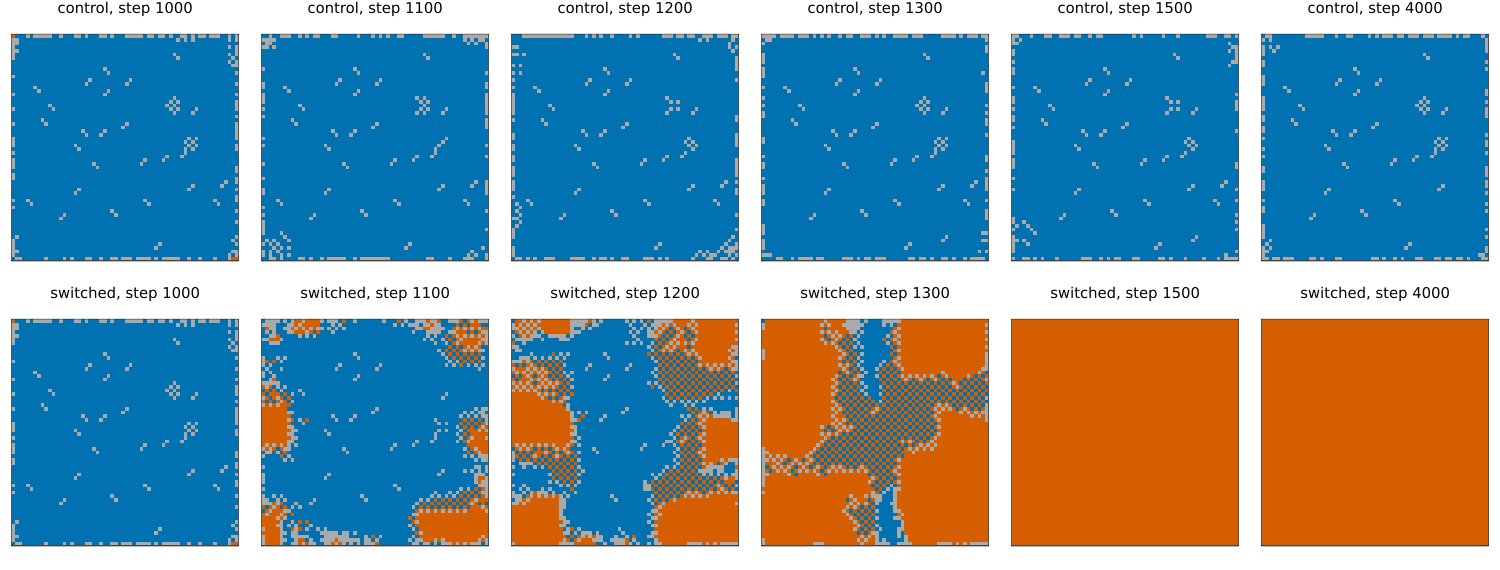

In [5]:
let

    # draw the top row: the control at each step -
    panels = [];
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(live.control.frames[t]; colors = intention_colors, title_text = "control, step $(t)"));
    end

    # draw the bottom row: the switched market at the same steps -
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(live.switched.frames[t]; colors = intention_colors, title_text = "switched, step $(t)"));
    end

    # show the two rows: the layout fills the top row first -
    number_of_steps = length(steps_to_visualize);
    plot(panels..., layout = (2, number_of_steps), size = (250*number_of_steps, 570), margin = 1Plots.mm)
end

The two markets have the same grid at the switch step. After the switch, every difference between the two rows comes from the traders who follow `switch_rule`.

Next, let's watch the two grids and the share price together. `Unhide` the code block below to see how we built the animation, which draws one frame every 20 steps with [the @animate macro](https://docs.juliaplots.org/stable/animations/):

Plots.AnimatedGif("/var/folders/82/m7j29m517p9c2201mdkk3m580000gp/T/jl_KxwjI3Qn6t.gif")
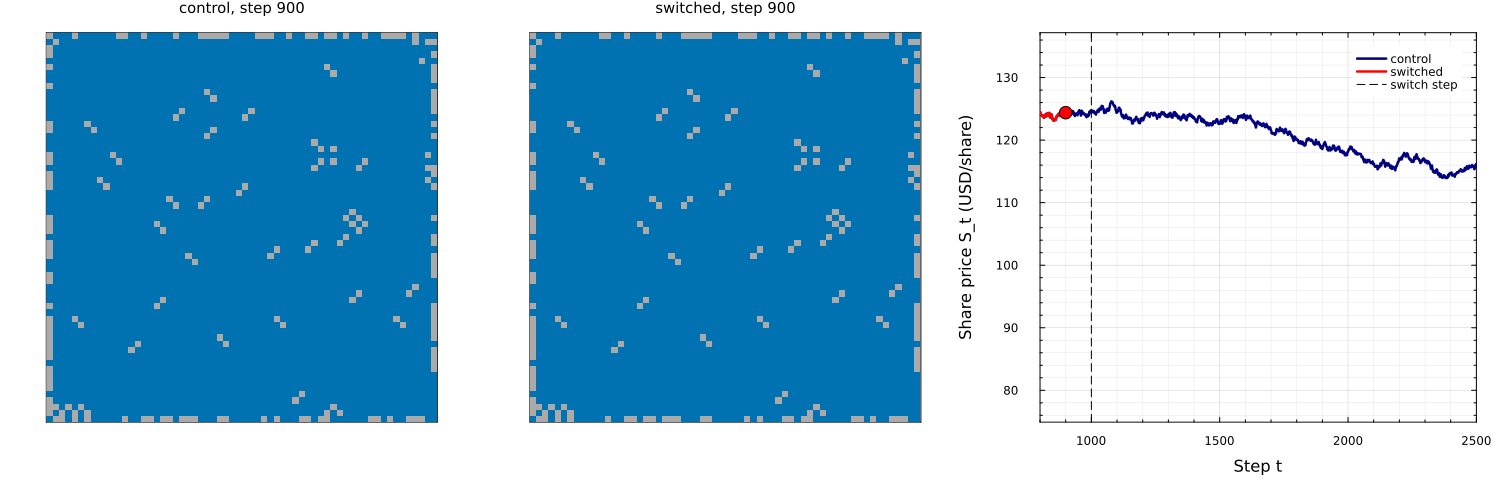

In [6]:
let

    # initialize: the steps we draw, from 100 steps before the switch to 1,400 steps after it -
    animation_steps = [t for t ∈ live.saved_steps if (t_pre - 100 <= t <= t_pre + 1400) && (t % 20 == 0)];
    all_steps = 0:(t_pre + t_post); # step numbers of the prices
    y_low = 0.95*minimum(live.switched.prices); # price axis limits, shared by every frame
    y_high = 1.08*maximum(live.switched.prices);

    # draw one frame for each step: the control grid, the switched grid, and the share price up to that step -
    animation = @animate for t ∈ animation_steps

        # left and center: the grids of the control and of the switched market -
        p_control = plot_grid(live.control.frames[t]; colors = intention_colors, title_text = "control, step $(t)");
        p_switched = plot_grid(live.switched.frames[t]; colors = intention_colors, title_text = "switched, step $(t)");

        # right: the control price, and the switched price up to step t -
        p_price = plot(all_steps, live.control.prices, lw = 2.5, c = color_control, label = "control",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, xlims = (t_pre - 200, t_pre + 1500), ylims = (y_low, y_high), legend = :topright);
        plot!(p_price, 0:t, live.switched.prices[1:(t + 1)], lw = 2.5, c = color_switched, label = "switched");
        scatter!(p_price, [t], [live.switched.prices[t + 1]], ms = 7, c = color_switched, label = "");
        vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
        xlabel!(p_price, "Step t", fontsize = 18);
        ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

        plot(p_control, p_switched, p_price, layout = (1, 3), size = (1500, 490), margin = 4Plots.mm, bottom_margin = 9Plots.mm)
    end

    # show the animation at 12 frames per second -
    gif(animation, tempname() * ".gif"; fps = 12, show_msg = false)
end

Your grids will differ if you change the parameters, because each `seed` gives a different starting market.

___

## Task 2: Follow the Share Price
In this task, we compare the share price of the switched market with its control, and ask why the price stops falling.

The dealer quotes the share price from its cash and shares. Net selling lowers the price, and net buying raises it. The __Sell fraction__ is the fraction of interior traders who intend to sell, and a market has a __Sell majority__ once the Sell fraction reaches one half after the switch.

`Unhide` the code block below to see how we plotted the intentions and the share price of the two markets from Task 1. Each strip on the left shows the fraction of interior traders who intend to buy, hold, and sell, in the colors of the grid. The top of the orange band is the Sell fraction, and the dotted line marks one half.

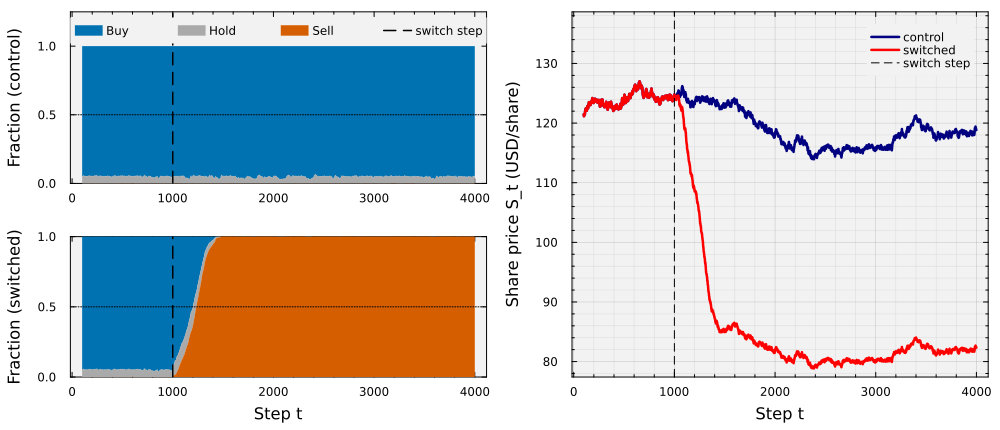

In [7]:
let

    # initialize: the steps we plot, and their positions in the saved series (step 0 is at position 1) -
    steps_to_plot = first_step_to_plot:(t_pre + t_post);
    positions = (first_step_to_plot + 1):(t_pre + t_post + 1);

    # left column: one strip for each market, the control above the switched market -
    markets_to_plot = [live.control, live.switched];
    names = ["control", "switched"];
    strips = [];
    for i ∈ eachindex(markets_to_plot)

        # the fractions of interior traders who intend to sell and to hold -
        sell = markets_to_plot[i].sell_fraction[positions];
        hold = markets_to_plot[i].hold_fraction[positions];
        top = ones(length(sell)); # the three fractions sum to one

        # only the top strip gets the legend and the room for it, and only the bottom strip gets the x-axis label -
        y_high = 1.0;
        legend_position = false;
        x_label = "Step t";
        if i == 1
            y_high = 1.25;
            legend_position = :top;
            x_label = "";
        end

        # fill three bands: Sell from 0 up, Hold above Sell, and Buy from the top of Hold up to 1 -
        p = plot(steps_to_plot, top, fillrange = sell .+ hold, lw = 0, c = intention_colors[1], label = "Buy",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, grid = false, ylims = (0.0, y_high), yticks = 0.0:0.5:1.0, legend = legend_position, legend_columns = 4);
        plot!(p, steps_to_plot, sell .+ hold, fillrange = sell, lw = 0, c = intention_colors[2], label = "Hold");
        plot!(p, steps_to_plot, sell, fillrange = 0.0, lw = 0, c = intention_colors[3], label = "Sell");
        hline!(p, [0.5], lw = 1, c = :black, ls = :dot, label = "");
        vline!(p, [t_pre], lw = 1.5, c = :black, ls = :dash, label = "switch step");
        xlabel!(p, x_label, fontsize = 18);
        ylabel!(p, "Fraction ($(names[i]))", fontsize = 18);
        push!(strips, p);
    end

    # right panel: the share price that the dealer quotes -
    p_price = plot(steps_to_plot, live.control.prices[positions], lw = 2.5, c = color_control, label = "control",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright);
    plot!(p_price, steps_to_plot, live.switched.prices[positions], lw = 2.5, c = color_switched, label = "switched");
    vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    (y_low, y_high) = ylims(p_price);
    ylims!(p_price, y_low, y_high + 0.2*(y_high - y_low)); # leave room for the legend
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two strips on the left and the share price on the right -
    plot(strips[1], strips[2], p_price, layout = @layout([[a{0.55h}; b] c]), size = (1000, 430), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

A trader can sell only the shares it holds, and each trader started with `10` shares.

`Unhide` the code block below to see how we plotted the orders in the switched market at each step: the Sell and Buy orders that the dealer filled, and the Sell orders that failed because the trader had no shares.

Why does the share price stop falling?

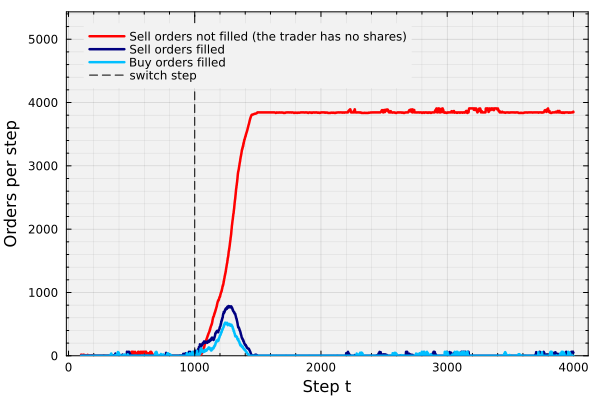

In [8]:
let

    # initialize: the steps we plot; there is one count for each step after step 0, and step t is at position t -
    steps_to_plot = max(first_step_to_plot, 1):(t_pre + t_post);
    market = live.switched;

    # plot: unfilled Sell orders, filled Sell orders, and filled Buy orders -
    q = plot(steps_to_plot, market.suppressed_sells[steps_to_plot], lw = 2.5, c = :red, label = "Sell orders not filled (the trader has no shares)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft);
    plot!(q, steps_to_plot, market.executed_sells[steps_to_plot], lw = 2.5, c = :navy, label = "Sell orders filled");
    plot!(q, steps_to_plot, market.executed_buys[steps_to_plot], lw = 2.5, c = :deepskyblue1, label = "Buy orders filled");
    vline!(q, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");

    # labels: leave room for the legend at the top of the axes -
    ylims!(q, 0, 1.35*ylims(q)[2]);
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Orders per step", fontsize = 18)
end

A Sell order fails when the trader has no shares left. When the filled Sell orders and the filled Buy orders are about equal, the net trade is close to zero, and only the noise moves the dealer's price.

One market is one starting market. Let's repeat the switch for 20 starting markets on a smaller grid, with the same parameters. We store the share prices of each switched market and its control in the `markets::Vector{NamedTuple}` variable:

In [9]:
markets = let

    # initialize: one entry for each starting market -
    results = NamedTuple[];

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # main loop: run the switched market and its control for each seed -
    t_run = @elapsed for s ∈ seeds
        pair = run_noisy_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, L = L_small, f = f, h = h, seed = s, boundary_mode = boundary_mode, σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, kw...);
        push!(results, (seed = s, switched = pair.switched.prices, control = pair.control.prices));
    end
    println("run time for $(length(seeds)) starting markets: $(round(t_run; digits = 1)) seconds");

    # checks -
    @assert length(results) == length(seeds) "one entry for each starting market"

    # return -
    results
end;

run time for 20 starting markets: 2.0 seconds


`Unhide` the code block below to see how we plotted the share price of every switched market and every control. Do all the starting markets end at the same share price?

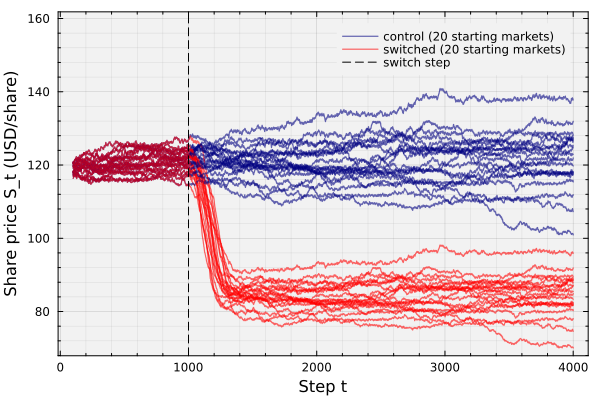

In [10]:
let

    # initialize: the steps we plot, and their positions in the saved series (step 0 is at position 1) -
    steps_to_plot = first_step_to_plot:(t_pre + t_post);
    positions = (first_step_to_plot + 1):(t_pre + t_post + 1);

    # plot: one thin line for each market; only the first line of each kind gets a legend entry -
    q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright);
    for m ∈ markets
        label_control = "";
        label_switched = "";
        if m.seed == first(seeds)
            label_control = "control ($(length(seeds)) starting markets)";
            label_switched = "switched ($(length(seeds)) starting markets)";
        end
        plot!(q, steps_to_plot, m.control[positions], lw = 1.2, c = color_control, alpha = 0.6, label = label_control);
        plot!(q, steps_to_plot, m.switched[positions], lw = 1.2, c = color_switched, alpha = 0.6, label = label_switched);
    end
    vline!(q, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");

    # labels: leave room for the legend at the top of the axes -
    (y_low, y_high) = ylims(q);
    ylims!(q, y_low, y_high + 0.25*(y_high - y_low));
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Share price S_t (USD/share)", fontsize = 18)
end

___

## Task 3: Bring in Fresh Players
In this task, we replace a fraction of the traders with fresh players after the share price has leveled off, and compare the share price with the run from Task 1.

After step `t_fresh`, __fresh players__ replace a fraction `fresh_fraction` of the interior traders. A fresh player starts with the cash and shares that every trader had at step `0`, and follows the rule `recovery_rule`. For example, a fresh player that follows Rule `0` intends to buy at every step.

The `run_noisy_rule_switch(...)` function runs the two markets of Task 1 again, with the fresh players. We store the two markets in the `recovery::NamedTuple` variable:

In [11]:
recovery = let

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the two markets of Task 1 again, with fresh players after step t_fresh -
    t_run = @elapsed pair = run_noisy_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode,
        σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, snapshot_steps = live.saved_steps,
        fresh_fraction = fresh_fraction, t_fresh = t_fresh, recovery_rule = recovery_rule, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds");

    # checks -
    @assert t_fresh % snapshot_every == 0 "the step t_fresh must be a saved step"
    @assert pair.switched.prices[1:(t_fresh + 1)] == live.switched.prices[1:(t_fresh + 1)] "the two runs must share their history until the fresh players arrive"

    # return -
    (switched = pair.switched, control = pair.control)
end;

run time: 0.7 seconds


`Unhide` the code block below to see how we plotted the intentions and the share price of the switched market, with and without the fresh players. The top strip shows the market without fresh players, and the bottom strip shows the market with fresh players.

Does the share price recover?

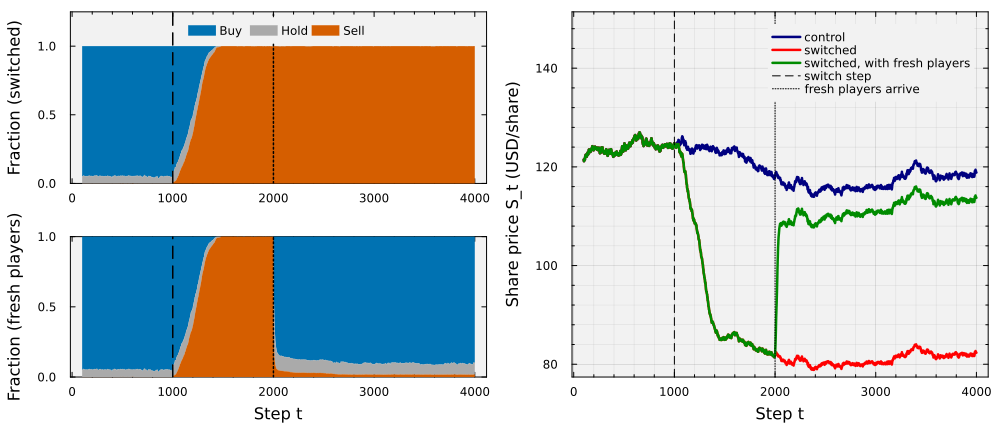

In [12]:
let

    # initialize: the steps we plot, and their positions in the saved series (step 0 is at position 1) -
    steps_to_plot = first_step_to_plot:(t_pre + t_post);
    positions = (first_step_to_plot + 1):(t_pre + t_post + 1);

    # left column: one strip for each switched market, without fresh players above and with fresh players below -
    markets_to_plot = [live.switched, recovery.switched];
    names = ["switched", "fresh players"];
    strips = [];
    for i ∈ eachindex(markets_to_plot)

        # the fractions of interior traders who intend to sell and to hold -
        sell = markets_to_plot[i].sell_fraction[positions];
        hold = markets_to_plot[i].hold_fraction[positions];
        top = ones(length(sell)); # the three fractions sum to one

        # only the top strip gets the legend and the room for it, and only the bottom strip gets the x-axis label -
        y_high = 1.0;
        legend_position = false;
        x_label = "Step t";
        if i == 1
            y_high = 1.25;
            legend_position = :top;
            x_label = "";
        end

        # fill three bands: Sell from 0 up, Hold above Sell, and Buy from the top of Hold up to 1 -
        p = plot(steps_to_plot, top, fillrange = sell .+ hold, lw = 0, c = intention_colors[1], label = "Buy",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, grid = false, ylims = (0.0, y_high), yticks = 0.0:0.5:1.0, legend = legend_position, legend_columns = 3);
        plot!(p, steps_to_plot, sell .+ hold, fillrange = sell, lw = 0, c = intention_colors[2], label = "Hold");
        plot!(p, steps_to_plot, sell, fillrange = 0.0, lw = 0, c = intention_colors[3], label = "Sell");
        vline!(p, [t_pre], lw = 1.5, c = :black, ls = :dash, label = "");
        vline!(p, [t_fresh], lw = 1.5, c = :black, ls = :dot, label = "");
        xlabel!(p, x_label, fontsize = 18);
        ylabel!(p, "Fraction ($(names[i]))", fontsize = 18);
        push!(strips, p);
    end

    # right panel: the share price that the dealer quotes; the legend names the vertical lines of every panel -
    p_price = plot(steps_to_plot, live.control.prices[positions], lw = 2.5, c = color_control, label = "control",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright);
    plot!(p_price, steps_to_plot, live.switched.prices[positions], lw = 2.5, c = color_switched, label = "switched");
    plot!(p_price, steps_to_plot, recovery.switched.prices[positions], lw = 2.5, c = color_fresh, label = "switched, with fresh players");
    vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    vline!(p_price, [t_fresh], lw = 1, c = :black, ls = :dot, label = "fresh players arrive");
    (y_low, y_high) = ylims(p_price);
    ylims!(p_price, y_low, y_high + 0.45*(y_high - y_low)); # leave room for the legend
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two strips on the left and the share price on the right -
    plot(strips[1], strips[2], p_price, layout = @layout([[a{0.55h}; b] c]), size = (1000, 430), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

Up to step `t_fresh`, the two switched markets are the same market. After it, every difference between the red line and the green line comes from the fresh players.

Next, let's look at the grid of the switched market at six steps, from the step `t_fresh` to the last step. The top row shows the market without fresh players, and the bottom row shows the market with fresh players:

In [13]:
steps_to_visualize_fresh = [t_fresh, t_fresh + 10, t_fresh + 20, t_fresh + 50, t_fresh + 200, t_pre + t_post]; # six saved steps, in order

`Unhide` the code block below to see how we drew the grids. Where do the intentions change first?

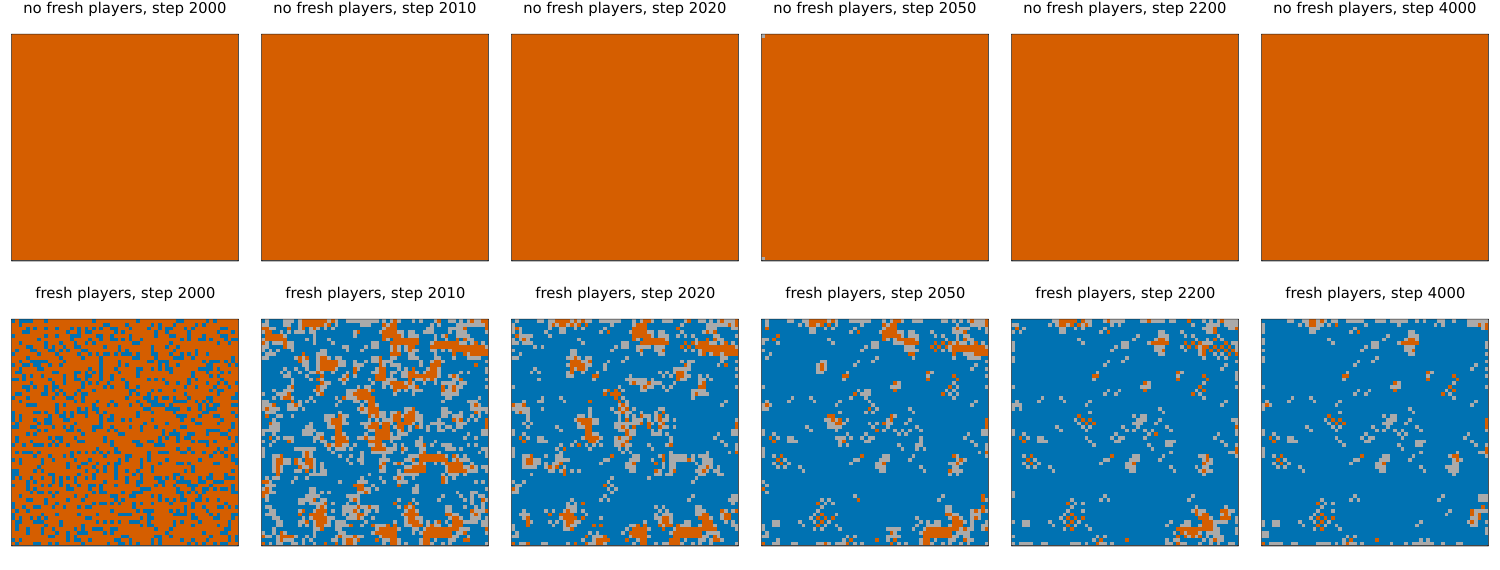

In [14]:
let

    # draw the top row: the switched market of Task 1, which gets no fresh players -
    panels = [];
    for t ∈ steps_to_visualize_fresh
        push!(panels, plot_grid(live.switched.frames[t]; colors = intention_colors, title_text = "no fresh players, step $(t)"));
    end

    # draw the bottom row: the switched market with fresh players at the same steps -
    for t ∈ steps_to_visualize_fresh
        push!(panels, plot_grid(recovery.switched.frames[t]; colors = intention_colors, title_text = "fresh players, step $(t)"));
    end

    # show the two rows: the layout fills the top row first -
    number_of_steps = length(steps_to_visualize_fresh);
    plot(panels..., layout = (2, number_of_steps), size = (250*number_of_steps, 570), margin = 1Plots.mm)
end

Set `recovery_rule = baseline_rule` to give the fresh players the rule from before the switch, and run the cells of Task 3 again.

___

## Summary
In this example, we watched a rule switch spread across the grid of a Wolfram market, followed the share price as it fell and leveled off, and brought in fresh players to move the share price again.

> __Key Takeaways:__
>
> * __A rule switch spreads from neighbor to neighbor:__ We ran a switched market and its control, and looked at the grid at several steps. Each trader acts on the intentions of its four neighbors, and a change in the switching traders reaches the rest of the grid through their neighbors.
> * __The share price falls until the sellers run out of shares:__ We compared the share price of the switched market with its control, and counted the filled and unfilled orders. A trader can sell only the shares it holds, and the price levels off once the filled Sell orders and the filled Buy orders are about equal.
> * __The recovery rule sets the direction of the share price:__ We replaced a fraction of the traders with fresh players, who start with new cash and shares and follow a recovery rule. Fresh players who intend to buy raise the share price, and fresh players who intend to sell lower it.

We can now change the rules, the fraction of switching traders, the fresh players, the dealer's depth and noise, the edge traders, the time step, and the starting market, and watch how the grid and the share price respond.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___